In [1]:
import sys
sys.path.append("../")

import time
from optlib.second_order import newton
from problems.testfuncs import Rosenbrock2d, RosenbrockNd, Quadratic, make_quadratic
import numpy as np

SEED=0
rng = np.random.default_rng(SEED)
tol=1e-8

# 2.1 - 2.2 Newton & Damping

In [2]:
r_2d = Rosenbrock2d()
r_nd = RosenbrockNd()

In [3]:
xk_set = []
while True:
    x = rng.random(size=2, dtype=float)
    try:
        np.linalg.cholesky(r_2d.hess(x))
    except np.linalg.LinAlgError:
        xk_set.append(x)
        if len(xk_set)==5:
            break

for xk in xk_set:
    print(xk)

[0.04097352 0.01652764]
[0.81327024 0.91275558]
[0.60663578 0.72949656]
[0.54362499 0.93507242]
[0.29971189 0.42268722]


In [4]:
from optlib.second_order import NewtonOptimizer
nwt_damping = NewtonOptimizer(damping=True)
nwt = NewtonOptimizer(damping=False) 
nwt_results = [nwt.minimize(r_2d, xk) for i,xk in enumerate(xk_set)]
nwt_damping_results = [nwt_damping.minimize(r_2d, xk) for i,xk in enumerate(xk_set)]

In [5]:
for res in nwt_damping_results:
    print(res.history["info"])

[{'tav': 4.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}]
[{'tav': 32.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}]
[{'tav': 128.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}]
[{'tav': 256.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}]
[{'tav': 128.0}, {'tav': 8.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}, {'tav': 0.0}]


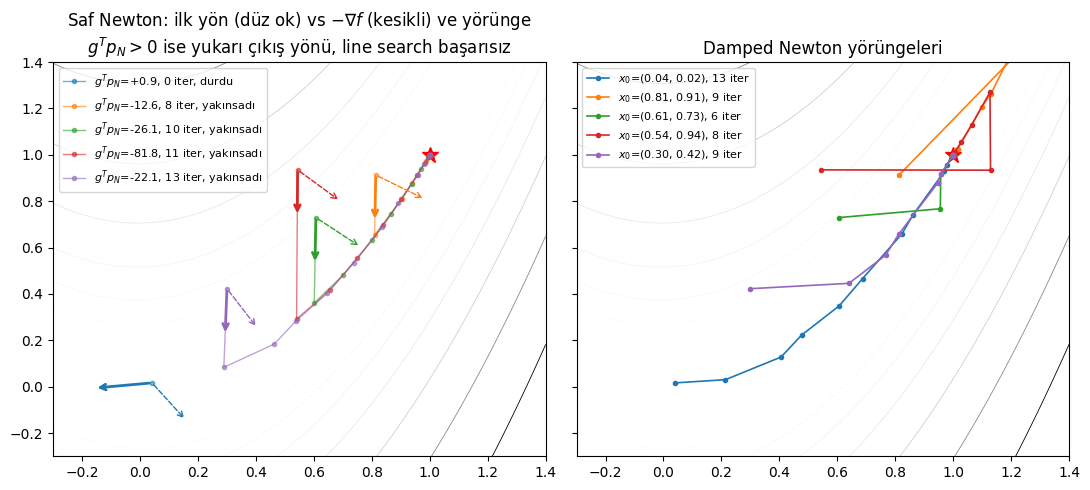

In [6]:
import matplotlib.pyplot as plt

# Hessian'ın PD olmadığı noktalarda saf Newton vs damped Newton
X, Y = np.meshgrid(np.linspace(-0.3, 1.4, 400), np.linspace(-0.3, 1.4, 400))
Z = (1 - X)**2 + 100*(Y - X**2)**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax in (ax1, ax2):
    ax.contour(X, Y, Z, levels=np.logspace(-2, 2.5, 18), cmap="Greys", linewidths=0.6)
    ax.plot(1, 1, "r*", ms=12)
    ax.set_xlim(-0.3, 1.4); ax.set_ylim(-0.3, 1.4)

L = 0.2  # ok uzunluğu (sadece yön gösteriliyor)
for i, xk in enumerate(xk_set):
    c = f"C{i}"
    p_N, _ = newton(r_2d, xk, damping_on=False)
    g = r_2d.grad(xk)
    P = np.array(nwt_results[i].history["x"])
    ax1.plot(P[:, 0], P[:, 1], "o-", color=c, ms=3, lw=1, alpha=0.6,
             label=f"$g^Tp_N$={g @ p_N:+.1f}, {nwt_results[i].n_iter} iter, "
                   + ("yakınsadı" if nwt_results[i].converged else "durdu"))
    ax1.annotate("", xy=xk + L*p_N/np.linalg.norm(p_N), xytext=xk,
                 arrowprops=dict(arrowstyle="->", color=c, lw=2))
    ax1.annotate("", xy=xk - L*g/np.linalg.norm(g), xytext=xk,
                 arrowprops=dict(arrowstyle="->", color=c, lw=1, ls="--"))

    P = np.array(nwt_damping_results[i].history["x"])
    ax2.plot(P[:, 0], P[:, 1], "o-", color=c, ms=3, lw=1.2,
             label=f"$x_0$=({xk[0]:.2f}, {xk[1]:.2f}), {nwt_damping_results[i].n_iter} iter")

ax1.set_title("Saf Newton: ilk yön (düz ok) vs $-\\nabla f$ (kesikli) ve yörünge\n$g^T p_N > 0$ ise yukarı çıkış yönü, line search başarısız")
ax1.legend(fontsize=8)
ax2.set_title("Damped Newton yörüngeleri")
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

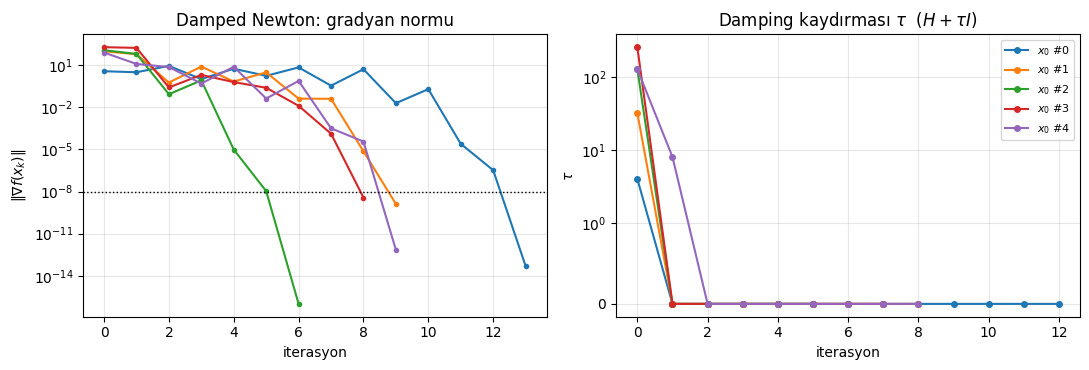

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for i, res in enumerate(nwt_damping_results):
    ax1.semilogy(np.maximum(res.history["gradnorm"], 1e-16), "o-", ms=3, color=f"C{i}")
    tav = [d["tav"] for d in res.history["info"]]
    ax2.plot(tav, "o-", ms=4, color=f"C{i}", label=f"$x_0$ #{i}")
ax1.axhline(tol, color="k", ls=":", lw=1)
ax1.set_xlabel("iterasyon"); ax1.set_ylabel(r"$\|\nabla f(x_k)\|$")
ax1.set_title("Damped Newton: gradyan normu")
ax2.set_yscale("symlog", linthresh=1)
ax2.set_xlabel("iterasyon"); ax2.set_ylabel(r"$\tau$")
ax2.set_title(r"Damping kaydırması $\tau$  ($H + \tau I$)")
ax2.legend(fontsize=8)
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

# 2.3 BFGS

In [6]:
from optlib.second_order import BFGS
bfgs = BFGS()
x0 = rng.random(10)

t1 = time.perf_counter()
res_bfgs = bfgs.minimize(r_nd, x0, max_iter=10000)
t2 = time.perf_counter()
res_nwtn = NewtonOptimizer(damping=True).minimize(r_nd, x0)
t3 = time.perf_counter()

print(f"Newton converged: {res_nwtn.converged}: {t3-t2}: {res_nwtn.n_iter}")
print(f"BFGS   converged: {res_bfgs.converged}: {t2-t1}: {res_bfgs.n_iter}")

Newton converged: True: 0.0014300270013336558: 14
BFGS   converged: True: 0.005428840999229578: 70


# 2.4 Linear Conjugate Gradient Method

In [8]:
from optlib.first_order import LinearCG
lcg = LinearCG()

In [9]:
n_set = [5, 20, 100]
kappa_set = [10, 10**2, 10**4, 10**6]

A_set = [make_quadratic(n, kappa) for kappa in kappa_set for n in n_set]
Q_set = [Quadratic(A) for A in A_set]
x0_set = [rng.standard_normal(n) for n in n_set]
x0_set.extend(x0_set)
x0_set.extend(x0_set)
len(x0_set)

12

In [10]:
lcg_results = [lcg.minimize(Q, x0, tol=tol) for Q,x0 in zip(Q_set, x0_set)]

In [11]:
for res in lcg_results:
    print(res.x.shape[0])
    print(f"Converged: {res.converged} in {res.n_iter}")

5
Converged: True in 5
20
Converged: True in 19
100
Converged: True in 27
5
Converged: True in 5
20
Converged: True in 23
100
Converged: True in 67
5
Converged: True in 6
20
Converged: True in 35
100
Converged: True in 257
5
Converged: True in 6
20
Converged: True in 52
100
Converged: True in 740


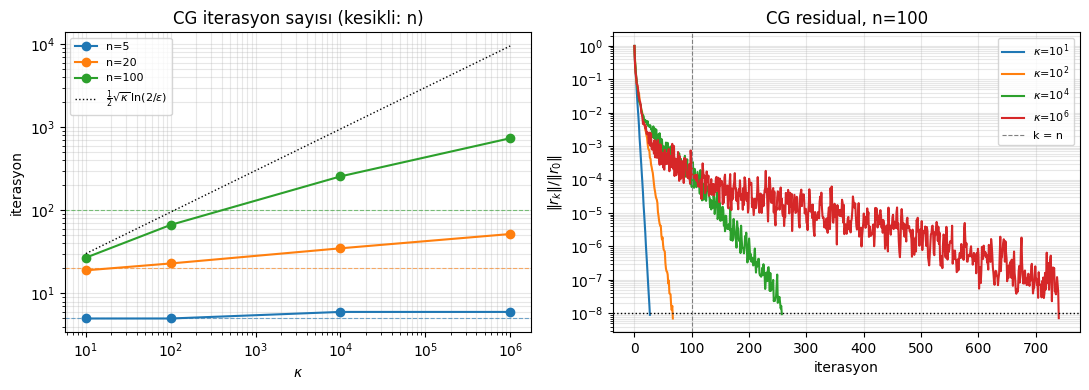

In [12]:
import matplotlib.pyplot as plt

# lcg_results sırası: kappa dış döngü, n iç döngü
iters = np.array([r.n_iter for r in lcg_results]).reshape(len(kappa_set), len(n_set))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for j, n in enumerate(n_set):
    line, = ax1.loglog(kappa_set, iters[:, j], "o-", label=f"n={n}")
    ax1.axhline(n, color=line.get_color(), ls="--", lw=0.8, alpha=0.6)
ks = np.array(kappa_set, dtype=float)
ax1.loglog(ks, 0.5*np.sqrt(ks)*np.log(2/tol), "k:", lw=1, label=r"$\frac{1}{2}\sqrt{\kappa}\,\ln(2/\epsilon)$")
ax1.set_xlabel(r"$\kappa$"); ax1.set_ylabel("iterasyon")
ax1.set_title("CG iterasyon sayısı (kesikli: n)")
ax1.legend(fontsize=8)

# n=100 için göreli residual (LinearCG durma kriteri: ||r_k|| < tol * ||r_0||)
j = n_set.index(100)
for i, kappa in enumerate(kappa_set):
    res = lcg_results[i*len(n_set) + j]
    rn = np.asarray(res.history["gradnorm"])
    ax2.semilogy(rn / rn[0], label=fr"$\kappa$=$10^{{{int(np.log10(kappa))}}}$")
ax2.axhline(tol, color="k", ls=":", lw=1)
ax2.axvline(100, color="gray", ls="--", lw=0.8, label="k = n")
ax2.set_xlabel("iterasyon"); ax2.set_ylabel(r"$\|r_k\| / \|r_0\|$")
ax2.set_title("CG residual, n=100")
ax2.legend(fontsize=8)
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()